# Loan Default Risk Prediction
## Member 3 — Model Development and Evaluation

### 1. Objective

Develop and evaluate classification models that predict whether a loan applicant is likely to experience repayment difficulties. This notebook continues from Member 2's preprocessing and feature-engineering work and uses the processed datasets supplied by that stage.

### 2. Models

1. **Logistic Regression** — baseline classifier.
2. **Random Forest** — tree-based classifier.
3. **XGBoost** — gradient-boosting classifier.

Logistic Regression is tuned with `GridSearchCV`. The models are compared using the same validation dataset.

### 3. Evaluation

Metrics include accuracy, precision, recall, F1-score, ROC-AUC, and confusion matrices. Accuracy is not used as the only selection criterion because the target classes are imbalanced.

### 4. Target

- `TARGET = 0`: No repayment difficulty recorded.
- `TARGET = 1`: Repayment difficulty recorded.

### 5. Reproducibility

The notebook uses a fixed random seed where applicable. Processed data, saved models, and reports are expected to be stored in the project folders shown by the setup cell.

In [88]:
from pathlib import Path
import json
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

RANDOM_STATE = 42

cwd = Path.cwd()
candidate_roots = [cwd, cwd.parent]
PROJECT_DIR = next(
    (candidate for candidate in candidate_roots
     if (candidate / "outputs" / "train_processed.pkl").exists()),
    cwd.parent
)

OUTPUT_DIR = PROJECT_DIR / "outputs"
MODEL_DIR = PROJECT_DIR / "models"
REPORT_DIR = PROJECT_DIR / "reports"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

if not (OUTPUT_DIR / "train_processed.pkl").exists():
    raise FileNotFoundError(
        f"Could not find processed training data at "
        f"{OUTPUT_DIR / 'train_processed.pkl'}. "
        "Check that the notebook is inside the project or notebooks folder."
    )

print("Project directory:", PROJECT_DIR.resolve())
print("Outputs directory:", OUTPUT_DIR.resolve())
print("Models directory:", MODEL_DIR.resolve())
print("Reports directory:", REPORT_DIR.resolve())

Project directory: D:\mem2submission\member2_submission
Outputs directory: D:\mem2submission\member2_submission\outputs
Models directory: D:\mem2submission\member2_submission\models
Reports directory: D:\mem2submission\member2_submission\reports


In [89]:
train_df = pd.read_pickle(
    OUTPUT_DIR / "train_processed.pkl"
)

valid_df = pd.read_pickle(
    OUTPUT_DIR / "valid_processed.pkl"
)

print("Training shape:", train_df.shape)
print("Validation shape:", valid_df.shape)

Training shape: (246008, 227)
Validation shape: (61503, 227)


### 5. Loading the Processed Datasets

The processed datasets are loaded from the
project's `outputs` directory.

The training dataset contains 246,008 rows and 227 columns.
The validation dataset contains 61,503 rows and 227 columns.

The datasets contain 226 input features and one target column.

The existing training-validation split is retained to ensure
consistency with the preprocessing stage.

In [90]:
# Separate features and target

X_train = train_df.drop(columns=["TARGET"])
y_train = train_df["TARGET"]

X_valid = valid_df.drop(columns=["TARGET"])
y_valid = valid_df["TARGET"]

# Check dimensions
print("Training features:", X_train.shape)
print("Training target:", y_train.shape)

print("Validation features:", X_valid.shape)
print("Validation target:", y_valid.shape)

# Check target distribution
print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nValidation target distribution:")
print(y_valid.value_counts())

# Check target percentages
print("\nTraining target percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nValidation target percentages:")
print((y_valid.value_counts(normalize=True) * 100).round(2))

# Check feature consistency
assert list(X_train.columns) == list(X_valid.columns)

print("\nFeature columns match successfully!")

Training features: (246008, 226)
Training target: (246008,)
Validation features: (61503, 226)
Validation target: (61503,)

Training target distribution:
TARGET
0    226148
1     19860
Name: count, dtype: int64

Validation target distribution:
TARGET
0    56538
1     4965
Name: count, dtype: int64

Training target percentages:
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64

Validation target percentages:
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64

Feature columns match successfully!


### Dataset Validation

The training and validation datasets contain the same 226 input
features in the same order.

The positive class represents approximately 8.07% of the observations,
while the negative class represents approximately 91.93%.

This class imbalance makes accuracy alone insufficient for evaluating
the models. Precision, recall, F1-score, ROC-AUC, and confusion
matrices are therefore used for evaluation.

The class distribution is documented without applying a dedicated
resampling or class-weighting technique.

## 6. Logistic Regression — Baseline Model

Logistic Regression is used as the baseline classifier.

It estimates the probability that an applicant belongs to the positive
class, TARGET = 1.

The model provides a reference point for evaluating whether the
tree-based models improve classification performance.

The default classification threshold of 0.5 is used for the initial
evaluation.

In [91]:
from sklearn.linear_model import LogisticRegression
import time

# Initialize the model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
start_time = time.time()

lr_model.fit(X_train, y_train)

training_time = time.time() - start_time

print(f"Training completed in {training_time:.2f} seconds")

Training completed in 6.86 seconds


In [92]:
# Predict classes
y_pred_lr = lr_model.predict(X_valid)

# Predict probabilities of repayment difficulty
y_prob_lr = lr_model.predict_proba(X_valid)[:, 1]

print("First 10 predicted classes:")
print(y_pred_lr[:10])

print("\nFirst 10 predicted probabilities:")
print(y_prob_lr[:10])

First 10 predicted classes:
[0 0 0 0 0 0 0 0 0 0]

First 10 predicted probabilities:
[0.05115743 0.04150102 0.20920403 0.07279353 0.10652527 0.11656888
 0.0049469  0.00767773 0.37302486 0.06785626]


In [93]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

lr_accuracy = accuracy_score(y_valid, y_pred_lr)

lr_precision = precision_score(
    y_valid, y_pred_lr, zero_division=0
)

lr_recall = recall_score(
    y_valid, y_pred_lr, zero_division=0
)

lr_f1 = f1_score(
    y_valid, y_pred_lr, zero_division=0
)

lr_roc_auc = roc_auc_score(
    y_valid, y_prob_lr
)

print("LOGISTIC REGRESSION — VALIDATION RESULTS")
print("-" * 45)

print(f"Accuracy:  {lr_accuracy:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall:    {lr_recall:.4f}")
print(f"F1-score:  {lr_f1:.4f}")
print(f"ROC-AUC:   {lr_roc_auc:.4f}")

LOGISTIC REGRESSION — VALIDATION RESULTS
---------------------------------------------
Accuracy:  0.9198
Precision: 0.5805
Recall:    0.0240
F1-score:  0.0460
ROC-AUC:   0.7676


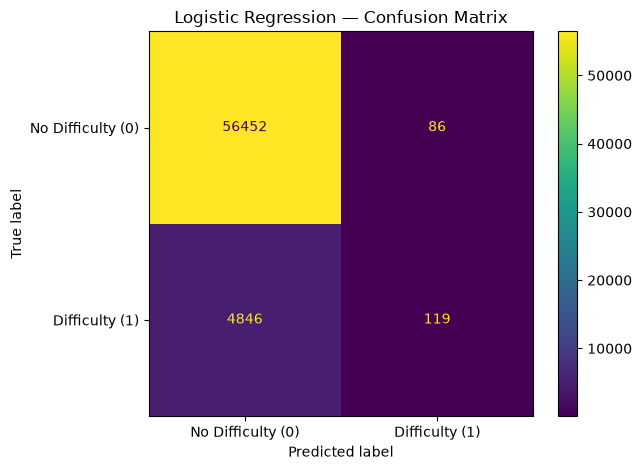

In [94]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_valid,
    y_pred_lr,
    display_labels=[
        "No Difficulty (0)",
        "Difficulty (1)"
    ],
    values_format="d"
)

plt.title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()

### Logistic Regression: Results and Interpretation

The model achieved a validation accuracy of approximately 91.98%
and a ROC-AUC of 0.7676.

However, its recall was only 2.40% at the default threshold of 0.5.

The confusion matrix shows that the model correctly identifies only
119 of the 4,965 positive validation cases.

The high accuracy is influenced by the predominance of the negative
class. Therefore, accuracy alone does not adequately describe the
model's ability to identify repayment difficulties.

These results establish the baseline for comparison with the
tree-based classifiers.

In [95]:
lr_results = {
    "Model": "Logistic Regression",
    "Accuracy": lr_accuracy,
    "Precision": lr_precision,
    "Recall": lr_recall,
    "F1-score": lr_f1,
    "ROC-AUC": lr_roc_auc,
    "Training Time (seconds)": training_time
}

print(lr_results)

{'Model': 'Logistic Regression', 'Accuracy': 0.9198087898151309, 'Precision': 0.5804878048780487, 'Recall': 0.023967774420946625, 'F1-score': 0.046034816247582204, 'ROC-AUC': 0.7676214701395744, 'Training Time (seconds)': 6.8626697063446045}


## 7. Random Forest Classifier

Random Forest is a tree-based classification algorithm that combines
predictions from multiple decision trees.

It can capture nonlinear relationships between applicant features
and the target variable.

The initial configuration uses 100 trees, a maximum depth of 16,
and a minimum leaf size of 5.

The model is evaluated on the same validation dataset as Logistic
Regression to enable a consistent comparison.

In [96]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=16,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=2
)

start_time = time.time()

rf_model.fit(X_train, y_train)

rf_training_time = time.time() - start_time

print(
    f"Random Forest training time: "
    f"{rf_training_time:.2f} seconds"
)

Random Forest training time: 70.50 seconds


In [97]:
y_pred_rf = rf_model.predict(X_valid)

y_prob_rf = rf_model.predict_proba(X_valid)[:, 1]

print("First 10 predicted classes:")
print(y_pred_rf[:10])

print("\nFirst 10 predicted probabilities:")
print(y_prob_rf[:10])

First 10 predicted classes:
[0 0 0 0 0 0 0 0 0 0]

First 10 predicted probabilities:
[0.05301182 0.04109511 0.23891284 0.06072648 0.10229142 0.10948049
 0.02485188 0.0225162  0.2979036  0.06885631]


In [98]:
rf_accuracy = accuracy_score(y_valid, y_pred_rf)

rf_precision = precision_score(
    y_valid, y_pred_rf, zero_division=0
)

rf_recall = recall_score(
    y_valid, y_pred_rf, zero_division=0
)

rf_f1 = f1_score(
    y_valid, y_pred_rf, zero_division=0
)

rf_roc_auc = roc_auc_score(
    y_valid, y_prob_rf
)

print("RANDOM FOREST — VALIDATION RESULTS")
print("-" * 45)

print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1-score:  {rf_f1:.4f}")
print(f"ROC-AUC:   {rf_roc_auc:.4f}")

RANDOM FOREST — VALIDATION RESULTS
---------------------------------------------
Accuracy:  0.9193
Precision: 0.5000
Recall:    0.0010
F1-score:  0.0020
ROC-AUC:   0.7591


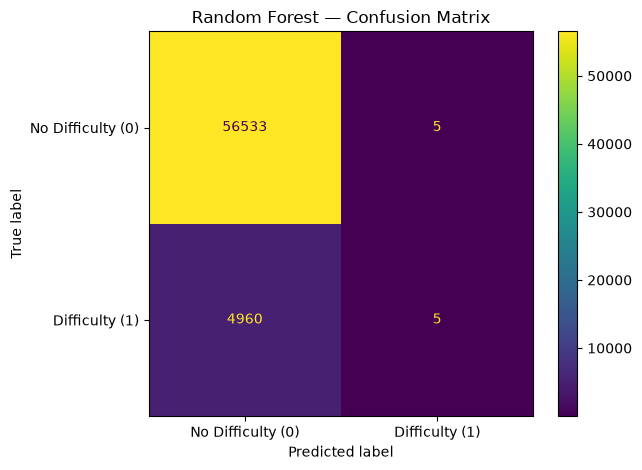

In [99]:
ConfusionMatrixDisplay.from_predictions(
    y_valid,
    y_pred_rf,
    display_labels=[
        "No Difficulty (0)",
        "Difficulty (1)"
    ],
    values_format="d"
)

plt.title("Random Forest — Confusion Matrix")
plt.tight_layout()
plt.show()

### Random Forest: Results and Interpretation

Random Forest achieved a validation accuracy of approximately 91.93%
and a ROC-AUC of 0.7591.

Its recall was approximately 0.10%, indicating that the model
identified only 5 of the 4,965 positive validation cases at the
default classification threshold.

Although its overall accuracy appears high, its ability to identify
the positive class is poor.

Random Forest therefore performs worse than Logistic Regression
and XGBoost on the current validation metrics.

In [100]:
rf_results = {
    "Model": "Random Forest",
    "Accuracy": rf_accuracy,
    "Precision": rf_precision,
    "Recall": rf_recall,
    "F1-score": rf_f1,
    "ROC-AUC": rf_roc_auc,
    "Training Time (seconds)": rf_training_time
}

print(rf_results)

{'Model': 'Random Forest', 'Accuracy': 0.9192722306228964, 'Precision': 0.5, 'Recall': 0.0010070493454179255, 'F1-score': 0.0020100502512562816, 'ROC-AUC': 0.7590741152195689, 'Training Time (seconds)': 70.49674844741821}


## 8. XGBoost Classifier

XGBoost is a gradient-boosting algorithm that builds decision trees
sequentially to improve predictive performance.

It is evaluated as the third classification model.

The initial configuration uses 250 estimators, a maximum tree depth
of 4, and a learning rate of 0.05.

The model is evaluated using the same training and validation
partitions used for the other classifiers.

In [101]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=250,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=2
)

start_time = time.time()

xgb_model.fit(X_train, y_train)

xgb_training_time = time.time() - start_time

print(
    f"XGBoost training time: "
    f"{xgb_training_time:.2f} seconds"
)

XGBoost training time: 17.63 seconds


In [102]:
y_pred_xgb = xgb_model.predict(X_valid)

y_prob_xgb = xgb_model.predict_proba(X_valid)[:, 1]

print("First 10 predicted classes:")
print(y_pred_xgb[:10])

print("\nFirst 10 predicted probabilities:")
print(y_prob_xgb[:10])

First 10 predicted classes:
[0 0 0 0 0 0 0 0 0 0]

First 10 predicted probabilities:
[0.04945413 0.04723488 0.31129038 0.06304907 0.09101856 0.11085422
 0.00904664 0.01243213 0.3551806  0.07874009]


In [103]:
xgb_accuracy = accuracy_score(
    y_valid, y_pred_xgb
)

xgb_precision = precision_score(
    y_valid, y_pred_xgb,
    zero_division=0
)

xgb_recall = recall_score(
    y_valid, y_pred_xgb,
    zero_division=0
)

xgb_f1 = f1_score(
    y_valid, y_pred_xgb,
    zero_division=0
)

xgb_roc_auc = roc_auc_score(
    y_valid, y_prob_xgb
)

print("XGBOOST — VALIDATION RESULTS")
print("-" * 45)

print(f"Accuracy:  {xgb_accuracy:.4f}")
print(f"Precision: {xgb_precision:.4f}")
print(f"Recall:    {xgb_recall:.4f}")
print(f"F1-score:  {xgb_f1:.4f}")
print(f"ROC-AUC:   {xgb_roc_auc:.4f}")

XGBOOST — VALIDATION RESULTS
---------------------------------------------
Accuracy:  0.9202
Precision: 0.6318
Recall:    0.0280
F1-score:  0.0536
ROC-AUC:   0.7802


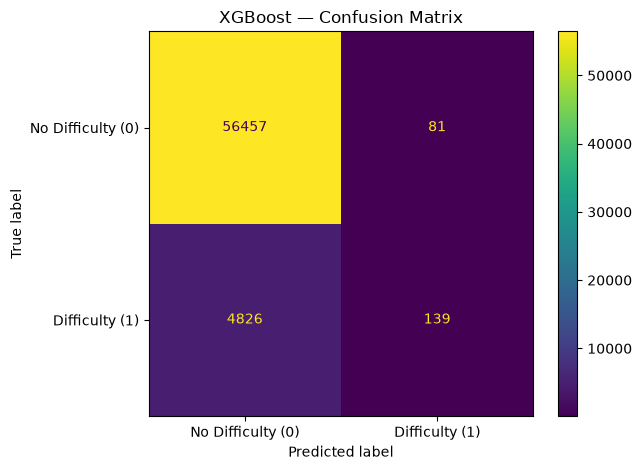

In [104]:
ConfusionMatrixDisplay.from_predictions(
    y_valid,
    y_pred_xgb,
    display_labels=[
        "No Difficulty (0)",
        "Difficulty (1)"
    ],
    values_format="d"
)

plt.title("XGBoost — Confusion Matrix")
plt.tight_layout()
plt.show()

### XGBoost: Results and Interpretation

XGBoost achieved a validation accuracy of 92.02%, precision of
63.18%, recall of 2.80%, F1-score of 5.36%, and ROC-AUC of 0.7802.

Among the three baseline models, XGBoost achieved the highest
validation ROC-AUC.

However, recall remained low at the default threshold of 0.5.
The model identified only 139 of the 4,965 positive validation cases.

XGBoost is selected as the leading model candidate based on its
validation ROC-AUC, subject to further evaluation of its
classification threshold and error trade-offs.

In [105]:
xgb_results = {
    "Model": "XGBoost",
    "Accuracy": xgb_accuracy,
    "Precision": xgb_precision,
    "Recall": xgb_recall,
    "F1-score": xgb_f1,
    "ROC-AUC": xgb_roc_auc,
    "Training Time (seconds)": xgb_training_time
}

results_df = pd.DataFrame([
    lr_results,
    rf_results,
    xgb_results
])

results_df = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training Time (seconds)
0,XGBoost,0.9202,0.6318,0.028,0.0536,0.7802,17.6289
1,Logistic Regression,0.9198,0.5805,0.024,0.0460,0.7676,6.8627
2,Random Forest,0.9193,0.5000,0.001,0.0020,0.7591,70.4967


In [106]:
REPORT_DIR.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    REPORT_DIR / "baseline_model_comparison.csv",
    index=False
)

print("Baseline comparison saved successfully.")

Baseline comparison saved successfully.


## 9. Baseline Model Comparison

The three classifiers are compared using the same validation dataset.

ROC-AUC measures how well a model ranks positive cases above negative
cases across classification thresholds.

Precision measures the proportion of predicted positive cases that
are actually positive. Recall measures the proportion of actual
positive cases correctly identified.

F1-score summarizes the balance between precision and recall.

Because the target distribution is imbalanced, accuracy is not
used as the sole model-selection criterion.

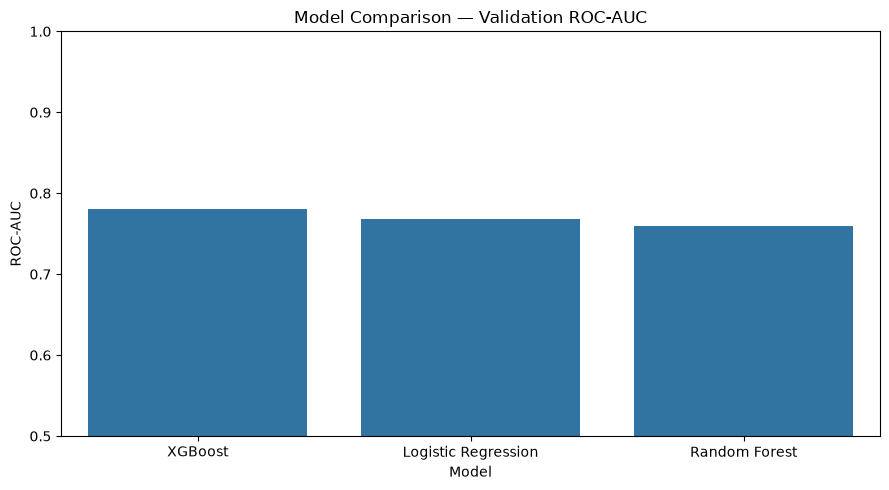

In [107]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="ROC-AUC"
)

plt.title("Model Comparison — Validation ROC-AUC")
plt.ylabel("ROC-AUC")
plt.xlabel("Model")
plt.ylim(0.5, 1.0)
plt.tight_layout()
plt.show()

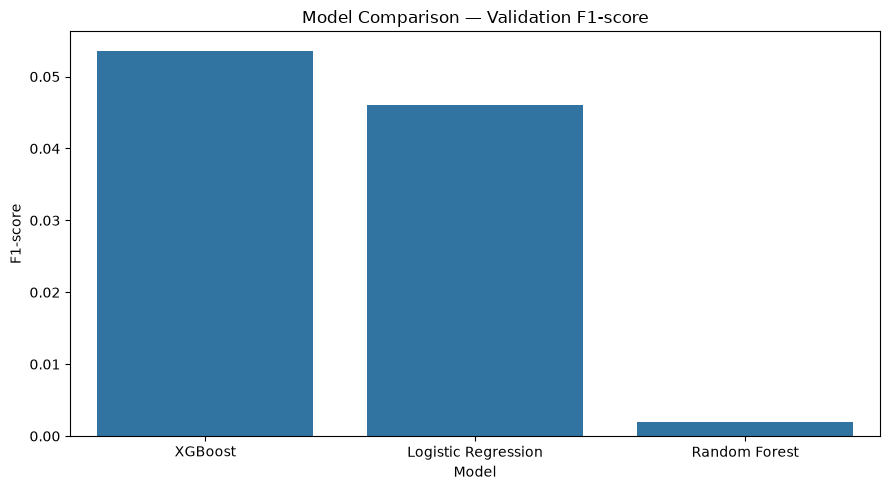

In [108]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="F1-score"
)

plt.title("Model Comparison — Validation F1-score")
plt.ylabel("F1-score")
plt.xlabel("Model")
plt.tight_layout()
plt.show()

### Comparison Findings

XGBoost achieved the highest baseline validation ROC-AUC of 0.7802,
followed by Logistic Regression at 0.7676 and Random Forest at 0.7591.

XGBoost also achieved the highest F1-score at the default threshold.

Logistic Regression required less training time than the two
tree-based models.

Random Forest showed particularly poor recall, identifying only
a small number of positive cases at the default threshold.

Based on the initial comparison, XGBoost is selected for further
evaluation.

## 10. Hyperparameter Tuning — Logistic Regression

GridSearchCV is used to tune the regularization parameter C of
Logistic Regression.

The candidate values are 0.1, 1.0, and 10.0.

Three-fold StratifiedKFold cross-validation is used to maintain
approximately consistent class proportions across the folds.

ROC-AUC is used as the cross-validation scoring metric.

The search is performed on the training dataset. The validation
dataset is retained for subsequent model evaluation.

In [109]:
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold
)

param_grid = {
    "C": [0.1, 1.0, 10.0]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=2,
    verbose=2
)

grid_search.fit(
    X_train,
    y_train
)

best_lr_model = grid_search.best_estimator_

print("Best parameters:", grid_search.best_params_)
print("Best CV ROC-AUC:", grid_search.best_score_)

Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best parameters: {'C': 0.1}
Best CV ROC-AUC: 0.7638910273071212


In [110]:
y_pred_tuned_lr = best_lr_model.predict(X_valid)

y_prob_tuned_lr = best_lr_model.predict_proba(X_valid)[:, 1]

tuned_lr_results = {
    "Model": "Logistic Regression (Tuned)",
    "Accuracy": accuracy_score(y_valid, y_pred_tuned_lr),
    "Precision": precision_score(
        y_valid, y_pred_tuned_lr, zero_division=0
    ),
    "Recall": recall_score(
        y_valid, y_pred_tuned_lr, zero_division=0
    ),
    "F1-score": f1_score(
        y_valid, y_pred_tuned_lr, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_valid, y_prob_tuned_lr)
}

display(pd.DataFrame([tuned_lr_results]).round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression (Tuned),0.9198,0.5792,0.0236,0.0453,0.7677


### Hyperparameter-Tuning Results

The search selected C = 0.1, with a mean cross-validation ROC-AUC
of approximately 0.7639.

The tuned Logistic Regression model is evaluated on the validation
dataset and compared with the baseline models.

The selected parameter provides the best cross-validation score
among the three tested values. It does not guarantee that the tuned
model will outperform the other classifiers.

In [111]:
model_candidates = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
    "Logistic Regression (Tuned)": best_lr_model
}

comparison_rows = []

for name, model in model_candidates.items():

    y_pred = model.predict(X_valid)
    y_prob = model.predict_proba(X_valid)[:, 1]

    comparison_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, y_pred),
        "Precision": precision_score(
            y_valid, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_valid, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_valid, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_valid, y_prob)
    })

final_comparison = pd.DataFrame(comparison_rows)

final_comparison = final_comparison.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(final_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,XGBoost,0.9202,0.6318,0.0280,0.0536,0.7802
1,Logistic Regression (Tuned),0.9198,0.5792,0.0236,0.0453,0.7677
2,Logistic Regression,0.9198,0.5805,0.0240,0.0460,0.7676
3,Random Forest,0.9193,0.5000,0.0010,0.0020,0.7591


In [112]:
final_comparison.to_csv(
    REPORT_DIR / "model_comparison.csv",
    index=False
)

print("Model comparison report saved.")

Model comparison report saved.


## 11. Final Model Selection

The baseline models and tuned Logistic Regression model are compared
using validation ROC-AUC.

The model with the highest validation ROC-AUC is selected as the
current best-performing candidate.

XGBoost achieved the highest validation ROC-AUC of 0.7802 and is
selected for further evaluation.

Other classification metrics are considered alongside ROC-AUC
because the target classes are imbalanced and the default
classification threshold produces low recall.

In [113]:
best_model_name = final_comparison.iloc[0]["Model"]

best_model = model_candidates[best_model_name]

print("Selected model:", best_model_name)
print(
    "Validation ROC-AUC:",
    round(final_comparison.iloc[0]["ROC-AUC"], 4)
)

Selected model: XGBoost
Validation ROC-AUC: 0.7802


In [114]:
import joblib
import json

MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "loan_default_model.pkl"

joblib.dump(best_model, model_path)

feature_path = MODEL_DIR / "model_feature_columns.json"

with open(feature_path, "w", encoding="utf-8") as f:
    json.dump(list(X_train.columns), f, indent=2)

print("Selected model:", best_model_name)
print("Model saved to:", model_path.resolve())
print("Feature schema saved to:", feature_path.resolve())

Selected model: XGBoost
Model saved to: D:\mem2submission\member2_submission\models\loan_default_model.pkl
Feature schema saved to: D:\mem2submission\member2_submission\models\model_feature_columns.json


### Saving the Selected Model

The selected XGBoost classifier is saved as
`models/loan_default_model.pkl`.

The ordered input feature names are saved separately in
`models/model_feature_columns.json`.

The classifier expects the 226 processed features generated by
Member 2's preprocessing pipeline.

The saved classifier must not be used directly with raw applicant
records unless those records have first been transformed using
the appropriate preprocessing steps.

## 12. Classification Threshold Analysis

The baseline XGBoost classifier uses a default classification threshold of 0.50. Since the positive class is a minority, this threshold can produce low recall.

The following experiment evaluates several thresholds using validation probabilities. It shows how accuracy, precision, recall, F1-score, and confusion-matrix counts change as the threshold changes.

The threshold with the highest F1-score among the tested values is retained as a candidate operating point. Because it is selected using the validation set, its reported performance should be treated as exploratory; a separate labelled test set should be reserved for final unbiased evaluation.

In [115]:
# Evaluate the same XGBoost probability scores at several thresholds.
y_prob = xgb_model.predict_proba(X_valid)[:, 1]

thresholds = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]
rows = []

for threshold in thresholds:
    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_valid, y_pred, labels=[0, 1]
    ).ravel()

    rows.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_valid, y_pred),
        "Precision": precision_score(y_valid, y_pred, zero_division=0),
        "Recall": recall_score(y_valid, y_pred, zero_division=0),
        "F1-score": f1_score(y_valid, y_pred, zero_division=0),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
    })

threshold_df = pd.DataFrame(rows)
display(threshold_df.round(4))

# Choose the tested threshold with the highest validation F1-score.
selected_threshold = float(
    threshold_df.loc[threshold_df["F1-score"].idxmax(), "Threshold"]
)
print("Selected threshold by validation F1-score:", selected_threshold)

,Threshold,Accuracy,Precision,Recall,F1-score,TN,FP,FN,TP
0,0.05,0.5508,0.1359,0.8522,0.2345,29647,26891,734,4231
1,0.10,0.7695,0.2025,0.6312,0.3066,44193,12345,1831,3134
2,0.15,0.8520,0.2619,0.4582,0.3333,50126,6412,2690,2275
3,0.20,0.8883,0.3151,0.3271,0.3210,53008,3530,3341,1624
4,0.25,0.9061,0.3703,0.2326,0.2857,54574,1964,3810,1155
5,0.30,0.9140,0.4162,0.1611,0.2323,55416,1122,4165,800
6,0.40,0.9195,0.5108,0.0713,0.1251,56199,339,4611,354
7,0.50,0.9202,0.6318,0.0280,0.0536,56457,81,4826,139


Selected threshold by validation F1-score: 0.15


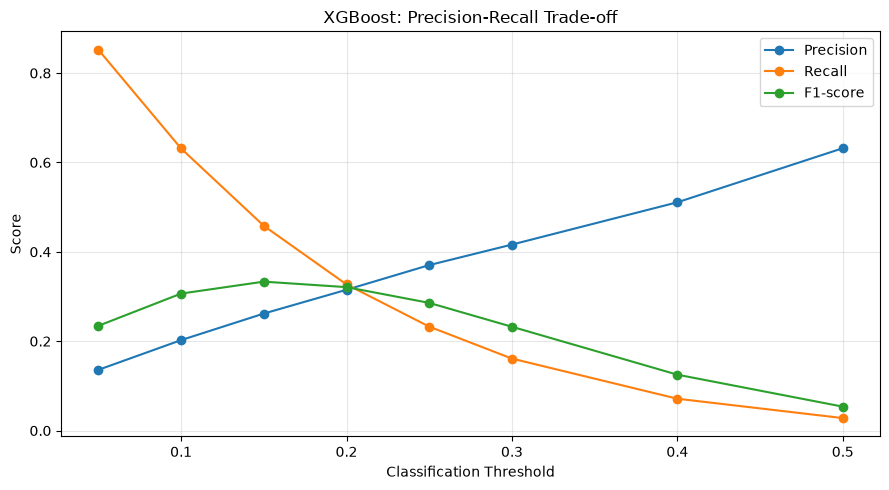

In [116]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1-score"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("XGBoost: Precision-Recall Trade-off")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Threshold Results and Interpretation

Among the eight thresholds tested, 0.15 achieved the highest F1-score in the supplied validation results (approximately 0.3333). At this threshold, the confusion matrix showed 50,126 true negatives, 6,412 false positives, 2,690 false negatives, and 2,275 true positives.

Compared with the default threshold of 0.50, the lower threshold identifies more positive cases but also increases false positives. The threshold is therefore a candidate operating point, not a universally optimal choice; the preferred trade-off depends on the relative costs of missed positive cases and false alarms.

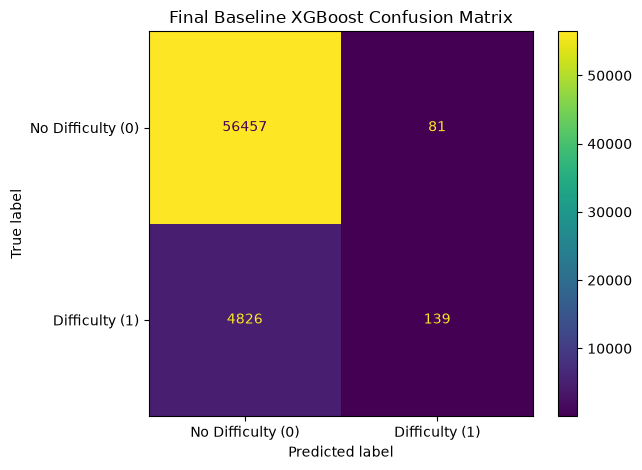

In [117]:
y_pred_xgb = xgb_model.predict(X_valid)

ConfusionMatrixDisplay.from_predictions(
    y_valid,
    y_pred_xgb,
    display_labels=[
        "No Difficulty (0)",
        "Difficulty (1)"
    ],
    values_format="d"
)

plt.title("Final Baseline XGBoost Confusion Matrix")
plt.tight_layout()
plt.show()

In [118]:
# Save the threshold comparison table.
threshold_df.to_csv(
    REPORT_DIR / "xgboost_threshold_analysis.csv",
    index=False
)

# Save the classification report at the default threshold of 0.50.
y_pred_default = xgb_model.predict(X_valid)

report_text = classification_report(
    y_valid,
    y_pred_default,
    target_names=["No Difficulty (0)", "Difficulty (1)"],
    digits=4,
    zero_division=0,
)

with open(
    REPORT_DIR / "xgboost_classification_report.txt",
    "w",
    encoding="utf-8",
) as f:
    f.write(report_text)

# Save the default-threshold confusion matrix.
cm_default = confusion_matrix(y_valid, y_pred_default, labels=[0, 1])
cm_default_df = pd.DataFrame(
    cm_default,
    index=["Actual_0", "Actual_1"],
    columns=["Predicted_0", "Predicted_1"],
)
cm_default_df.to_csv(REPORT_DIR / "xgboost_confusion_matrix.csv")

# Save the selected-threshold confusion matrix for comparison.
y_pred_selected = (
    xgb_model.predict_proba(X_valid)[:, 1] >= selected_threshold
).astype(int)

cm_selected = confusion_matrix(
    y_valid, y_pred_selected, labels=[0, 1]
)
pd.DataFrame(
    cm_selected,
    index=["Actual_0", "Actual_1"],
    columns=["Predicted_0", "Predicted_1"],
).to_csv(REPORT_DIR / "xgboost_confusion_matrix_threshold_015.csv")

print("Evaluation reports saved successfully.")

Evaluation reports saved successfully.


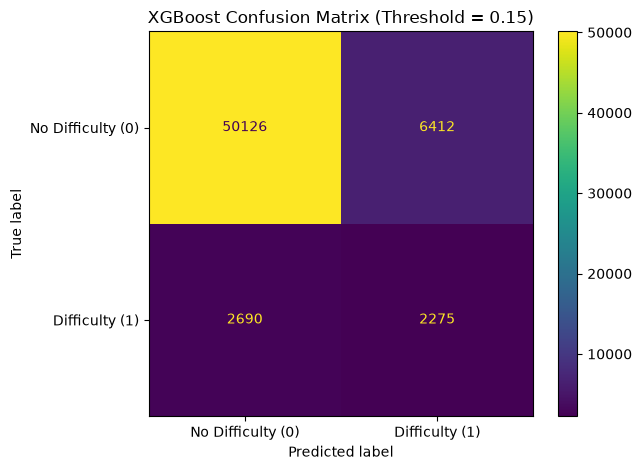

In [119]:
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay

# Use the threshold selected from the comparison table above.

y_pred_threshold = (
    xgb_model.predict_proba(X_valid)[:, 1]
    >= selected_threshold
).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_valid,
    y_pred_threshold,
    display_labels=[
        "No Difficulty (0)",
        "Difficulty (1)"
    ],
    values_format="d"
)

plt.title(
    f"XGBoost Confusion Matrix "
    f"(Threshold = {selected_threshold})"
)

plt.tight_layout()
plt.show()

In [120]:
# Keep the decision threshold alongside the saved model artifacts.
selected_threshold = 0.15

threshold_config = {
    "model": "XGBoost",
    "threshold": selected_threshold,
    "selection_metric": "F1-score",
    "selection_method": "Highest F1-score among the tested validation thresholds",
}

threshold_config_path = MODEL_DIR / "selected_threshold.json"
with open(threshold_config_path, "w", encoding="utf-8") as f:
    json.dump(threshold_config, f, indent=2)

print("Threshold configuration saved to:", threshold_config_path.resolve())

Threshold configuration saved to: D:\mem2submission\member2_submission\models\selected_threshold.json


## 13. Conclusion and Limitations

The three baseline classifiers were evaluated on the same validation dataset. XGBoost achieved the highest baseline validation ROC-AUC (0.7802), followed by Logistic Regression (0.7676) and Random Forest (0.7591). Logistic Regression was tuned using three-fold stratified GridSearchCV; the selected value was `C = 0.1`, with a mean cross-validation ROC-AUC of approximately 0.7639.

At the default threshold of 0.50, XGBoost achieved 92.02% accuracy, 63.18% precision, 2.80% recall, and an F1-score of 5.36%. Threshold analysis showed that lowering the threshold increases recall at the cost of more false positives. A threshold of 0.15 achieved the highest F1-score among the eight tested thresholds.

**Limitations**

- The target classes are imbalanced.
- Recall is low at the default threshold.
- Lower thresholds produce more false-positive predictions.
- The threshold was selected on the validation set, so final performance should be assessed on a separate labelled test set if available.
- Predictive associations and feature explanations should not be interpreted as proof of causal relationships.

The selected classifier, ordered feature schema, threshold configuration, and evaluation reports are saved for the next project stage. Do not pass raw applicant records directly to the classifier: apply Member 2's preprocessing pipeline first.